<a href="https://colab.research.google.com/github/Bteja272/ATLAS/blob/main/ATLAS_03_ML_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ATLAS 03 — ML Analysis and Labeling

This notebook consumes `atlas_reps_validated.csv` from Notebook 02.

Goals:
1. Build a clean rep-level feature matrix.
2. Inspect feature distributions and correlations.
3. Establish an unsupervised anomaly-detection baseline with Isolation Forest.
4. Create a labeling template for observable movement patterns.
5. Train supervised baselines only when enough labeled data exists.

ATLAS labels observable movement patterns; it does not diagnose injury or classify movements as medically safe/unsafe.


In [7]:
!pip -q install -U scikit-learn xgboost

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier

from google.colab import files

RANDOM_STATE = 42


## 1. Load validated rep data

Upload the `atlas_reps_validated.csv` produced by Notebook 02.


In [8]:
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("Upload atlas_reps_validated.csv from Notebook 02.")

uploaded_name = next(iter(uploaded))
REP_CSV = Path(uploaded_name)

reps_df = pd.read_csv(REP_CSV)

print("Loaded:", REP_CSV)
print("Shape:", reps_df.shape)
print("Columns:", list(reps_df.columns))

display(reps_df.head())


Saving atlas_reps_validated.csv to atlas_reps_validated (1).csv
Loaded: atlas_reps_validated (1).csv
Shape: (12, 25)
Columns: ['rep_number', 'start_frame', 'end_frame', 'start_time', 'peak_time', 'end_time', 'rep_duration', 'concentric_duration', 'eccentric_duration', 'left_elbow_rom', 'right_elbow_rom', 'mean_elbow_asymmetry', 'max_elbow_asymmetry', 'mean_torso_inclination', 'torso_variation', 'rom_asymmetry', 'set_progress', 'mean_elbow_rom', 'duration_valid', 'rom_valid', 'rep_valid', 'quality_score', 'torso_outlier', 'analysis_usable', 'original_rep_number']


,rep_number,start_frame,end_frame,start_time,peak_time,end_time,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,...,rom_asymmetry,set_progress,mean_elbow_rom,duration_valid,rom_valid,rep_valid,quality_score,torso_outlier,analysis_usable,original_rep_number
0,1,138,169,4.599974,4.999972,5.633302,1.033328,0.399998,0.633330,45.071363,...,21.085815,0.076923,34.528455,True,True,True,90.0,False,True,2
1,2,268,348,8.933284,10.399942,11.599935,2.666652,1.466658,1.199993,83.678461,...,10.991873,0.153846,78.182525,True,True,True,90.0,False,True,3
2,3,383,441,12.766596,14.033255,14.699918,1.933323,1.266660,0.666663,62.918567,...,18.329675,0.230769,72.083404,True,True,True,100.0,False,True,4
3,4,576,658,19.199893,19.566558,21.933211,2.733318,0.366665,2.366653,76.671980,...,1.120963,0.307692,76.111498,True,True,True,100.0,False,True,5
4,5,703,767,23.433203,23.833201,25.566524,2.133321,0.399998,1.733324,87.736454,...,21.233783,0.384615,77.119563,True,True,True,80.0,False,True,6


## 2. Select model features

Only rep-level movement measurements are used. Identifiers, timestamps, validation flags, and derived bookkeeping columns are excluded from the model feature matrix.


In [9]:
FEATURE_COLUMNS = [
    "rep_duration",
    "concentric_duration",
    "eccentric_duration",
    "left_elbow_rom",
    "right_elbow_rom",
    "mean_elbow_asymmetry",
    "max_elbow_asymmetry",
    "mean_torso_inclination",
    "torso_variation",
    "rom_asymmetry",
]

missing_features = [
    col for col in FEATURE_COLUMNS
    if col not in reps_df.columns
]

if missing_features:
    raise KeyError(
        f"Missing expected features from Notebook 02: {missing_features}"
    )

feature_df = reps_df[FEATURE_COLUMNS].copy()

print("Feature matrix shape:", feature_df.shape)
print("Missing values by feature:")
print(feature_df.isna().sum())

display(feature_df.describe().T)


Feature matrix shape: (12, 10)
Missing values by feature:
rep_duration              0
concentric_duration       0
eccentric_duration        0
left_elbow_rom            0
right_elbow_rom           0
mean_elbow_asymmetry      0
max_elbow_asymmetry       0
mean_torso_inclination    0
torso_variation           0
rom_asymmetry             0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
rep_duration,12.0,2.102766,0.935324,1.033328,1.649991,1.916656,2.266654,4.599974
concentric_duration,12.0,1.124994,0.791634,0.366665,0.574997,0.899995,1.491658,3.133316
eccentric_duration,12.0,0.977772,0.630266,0.233332,0.566664,0.883328,1.266660,2.366653
left_elbow_rom,12.0,70.164119,16.181698,34.314084,66.459713,75.755012,81.211799,87.736454
right_elbow_rom,12.0,61.727847,21.348979,23.985548,50.517722,66.988813,73.402696,99.871076
mean_elbow_asymmetry,12.0,11.951223,5.209733,5.045944,7.665140,11.425806,16.110968,19.032088
max_elbow_asymmetry,12.0,36.022202,13.804144,13.226754,25.534014,40.778621,43.759723,59.493307
mean_torso_inclination,12.0,38.088015,30.153099,5.152730,8.590241,36.443043,66.920296,76.006383
torso_variation,12.0,40.578907,36.133825,7.094079,15.035570,22.964787,72.946807,102.088839
rom_asymmetry,12.0,15.194336,10.071375,1.120963,7.751716,16.870190,21.122807,30.628370


## 3. Clean numerical feature matrix

Median imputation is used only for occasional missing numeric values. The original rep dataset remains unchanged.


In [10]:
X = feature_df.copy()

for col in FEATURE_COLUMNS:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X[col] = X[col].fillna(X[col].median())

if X.isna().any().any():
    raise RuntimeError("Feature matrix still contains missing values after imputation.")

print("Clean feature matrix:", X.shape)
display(X.head())


Clean feature matrix: (12, 10)


,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,max_elbow_asymmetry,mean_torso_inclination,torso_variation,rom_asymmetry
0,1.033328,0.399998,0.633330,45.071363,23.985548,7.491360,18.657042,65.177927,19.071154,21.085815
1,2.666652,1.466658,1.199993,83.678461,72.686589,5.325444,27.826338,60.779994,88.482888,10.991873
2,1.933323,1.266660,0.666663,62.918567,81.248242,7.723067,42.317393,76.006383,28.357402,18.329675
3,2.733318,0.366665,2.366653,76.671980,75.551017,13.895505,40.122324,8.884110,15.843483,1.120963
4,2.133321,0.399998,1.733324,87.736454,66.502672,8.956106,44.068825,9.219139,102.088839,21.233783


## 4. Feature distributions


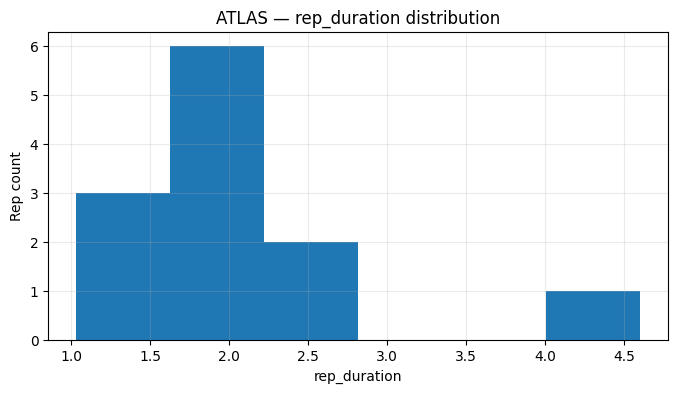

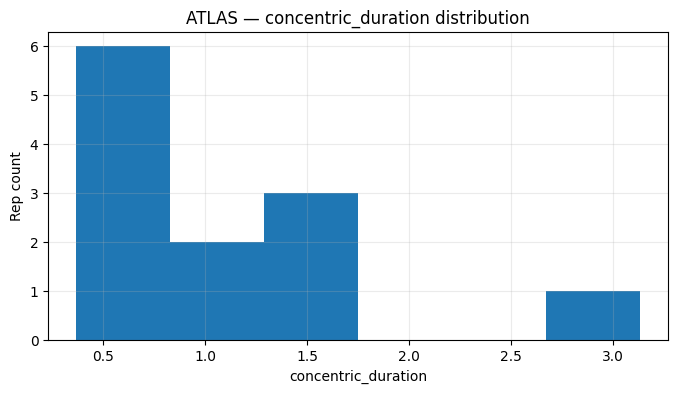

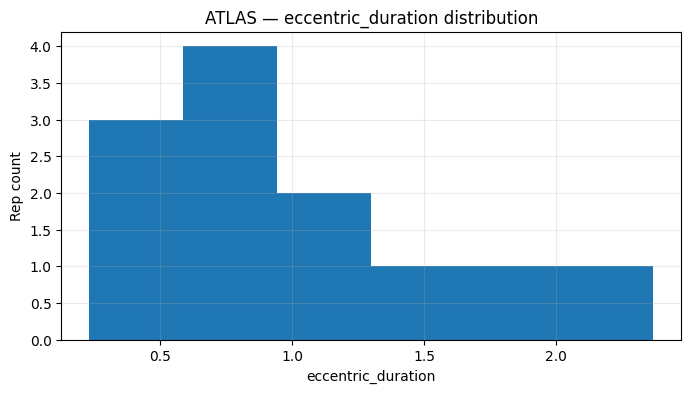

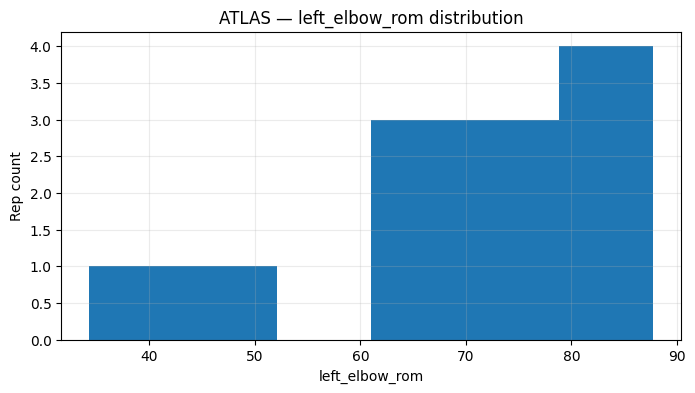

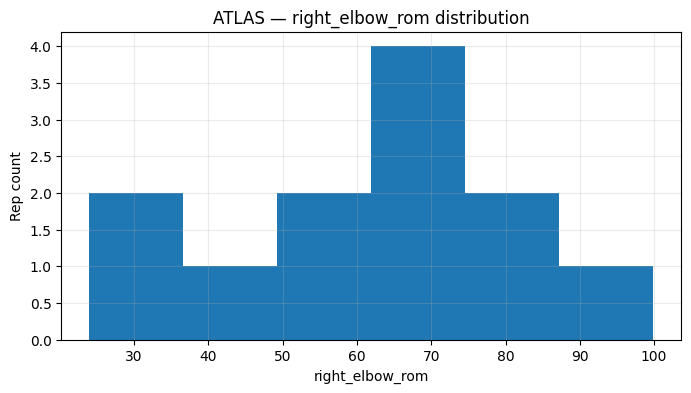

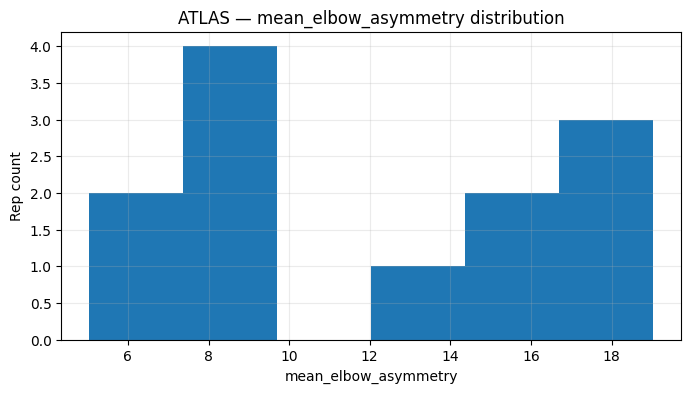

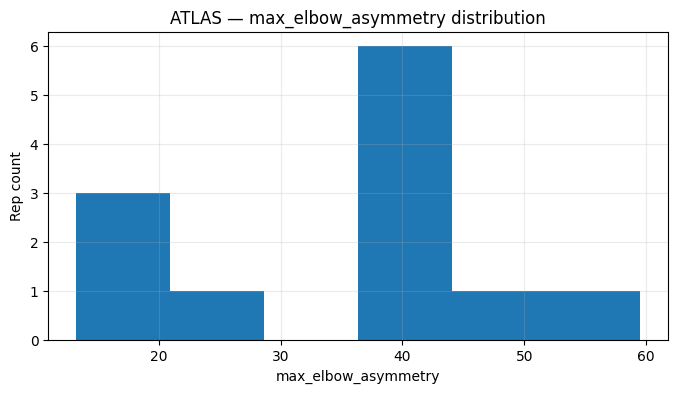

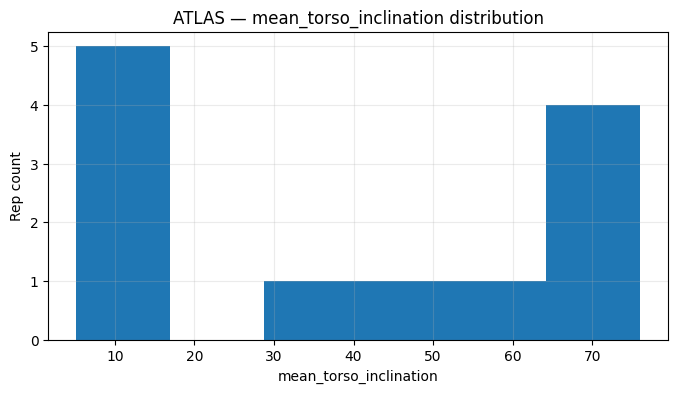

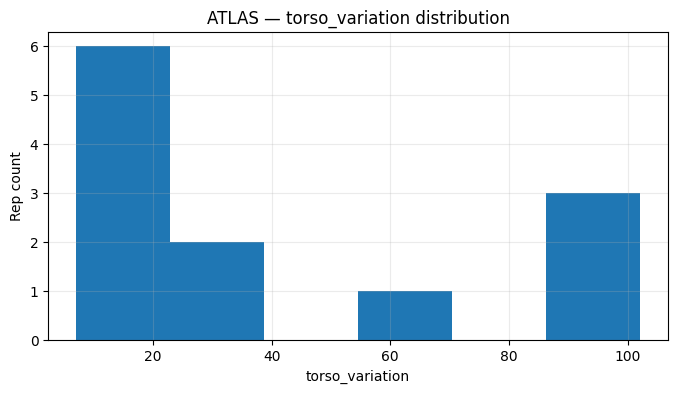

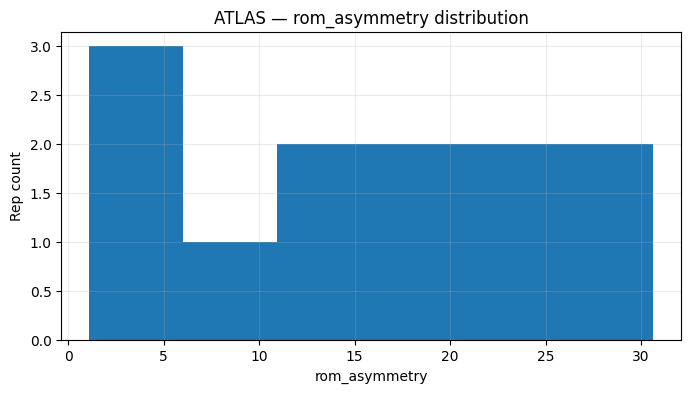

In [11]:
for column in FEATURE_COLUMNS:
    plt.figure(figsize=(8, 4))
    plt.hist(X[column], bins=min(10, max(3, len(X) // 2)))
    plt.xlabel(column)
    plt.ylabel("Rep count")
    plt.title(f"ATLAS — {column} distribution")
    plt.grid(alpha=0.25)
    plt.show()


## 5. Correlation inspection

With a small dataset, correlations are descriptive only. They are not evidence of causal relationships.


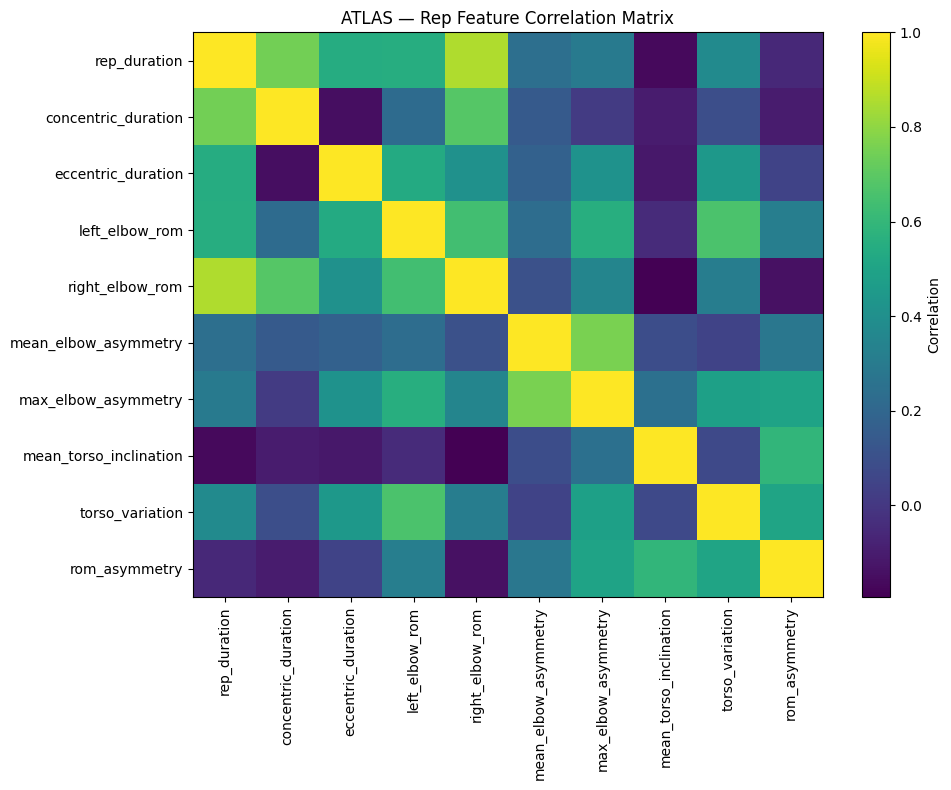

,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,max_elbow_asymmetry,mean_torso_inclination,torso_variation,rom_asymmetry
rep_duration,1.00,0.75,0.55,0.55,0.86,0.24,0.29,-0.16,0.38,-0.06
concentric_duration,0.75,1.00,-0.15,0.22,0.68,0.14,0.02,-0.10,0.09,-0.10
eccentric_duration,0.55,-0.15,1.00,0.54,0.41,0.18,0.42,-0.12,0.44,0.05
left_elbow_rom,0.55,0.22,0.54,1.00,0.64,0.23,0.55,-0.05,0.66,0.32
right_elbow_rom,0.86,0.68,0.41,0.64,1.00,0.10,0.35,-0.19,0.31,-0.14
mean_elbow_asymmetry,0.24,0.14,0.18,0.23,0.10,1.00,0.76,0.09,0.05,0.28
max_elbow_asymmetry,0.29,0.02,0.42,0.55,0.35,0.76,1.00,0.25,0.48,0.50
mean_torso_inclination,-0.16,-0.10,-0.12,-0.05,-0.19,0.09,0.25,1.00,0.07,0.59
torso_variation,0.38,0.09,0.44,0.66,0.31,0.05,0.48,0.07,1.00,0.50
rom_asymmetry,-0.06,-0.10,0.05,0.32,-0.14,0.28,0.50,0.59,0.50,1.00


In [12]:
corr = X.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("ATLAS — Rep Feature Correlation Matrix")
plt.tight_layout()
plt.show()

display(corr.round(2))


## 6. Standardize features

Scaling prevents features measured on larger numeric ranges from dominating the anomaly detector.


In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=FEATURE_COLUMNS,
    index=reps_df.index,
)

print("Scaled matrix shape:", X_scaled_df.shape)
display(X_scaled_df.head())


Scaled matrix shape: (12, 10)


,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,max_elbow_asymmetry,mean_torso_inclination,torso_variation,rom_asymmetry
0,-1.194231,-0.956545,-0.570805,-1.619640,-1.846484,-0.894129,-1.313904,0.938361,-0.621692,0.610984
1,0.629685,0.450785,0.368261,0.872298,0.536140,-1.328360,-0.620125,0.786022,1.384688,-0.435822
2,-0.189216,0.186911,-0.515565,-0.467672,0.955005,-0.847676,0.476314,1.313445,-0.353269,0.325155
3,0.704131,-1.000524,2.301632,0.420057,0.676277,0.389797,0.310228,-1.011587,-0.714990,-1.459499
4,0.034121,-0.956545,1.252088,1.134226,0.233601,-0.600472,0.608833,-0.999982,1.777975,0.626329


## 7. Isolation Forest baseline

This is an unsupervised personal/session anomaly detector. It does **not** determine whether a rep is correct or incorrect. It identifies reps whose measured feature patterns differ from the rest of the current session.

With only one small session, treat this as a technical baseline rather than a validated performance metric.


In [14]:
if len(X_scaled_df) < 8:
    raise RuntimeError(
        "Too few validated reps for a useful Isolation Forest baseline."
    )

iso_model = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=RANDOM_STATE,
)

iso_model.fit(X_scaled_df)

anomaly_prediction = iso_model.predict(X_scaled_df)
anomaly_score = -iso_model.score_samples(X_scaled_df)

ml_df = reps_df.copy()
ml_df["anomaly_score"] = anomaly_score
ml_df["is_session_anomaly"] = anomaly_prediction == -1

print("Session reps:", len(ml_df))
print("Anomaly candidates:", int(ml_df["is_session_anomaly"].sum()))

display(
    ml_df[
        [
            "rep_number",
            "rep_duration",
            "left_elbow_rom",
            "right_elbow_rom",
            "mean_elbow_asymmetry",
            "torso_variation",
            "anomaly_score",
            "is_session_anomaly",
        ]
    ].sort_values("anomaly_score", ascending=False)
)


Session reps: 12
Anomaly candidates: 5


,rep_number,rep_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,torso_variation,anomaly_score,is_session_anomaly
8,9,4.599974,80.389579,99.871076,17.100203,67.768113,0.556957,True
10,11,1.133327,34.314084,32.022021,8.939265,7.094079,0.542398,True
0,1,1.033328,45.071363,23.985548,7.491360,19.071154,0.526110,True
5,6,1.666657,84.125359,53.496989,19.032088,92.415026,0.507960,True
3,4,2.733318,76.671980,75.551017,13.895505,15.843483,0.503122,True
4,5,2.133321,87.736454,66.502672,8.956106,102.088839,0.498902,False
1,2,2.666652,83.678461,72.686589,5.325444,88.482888,0.490100,False
9,10,1.899989,76.898172,67.474954,5.045944,12.611832,0.482530,False
6,7,1.966656,67.640095,70.377306,15.781223,7.284497,0.477086,False
2,3,1.933323,62.918567,81.248242,7.723067,28.357402,0.458373,False


## 8. Visualize anomaly score through the set


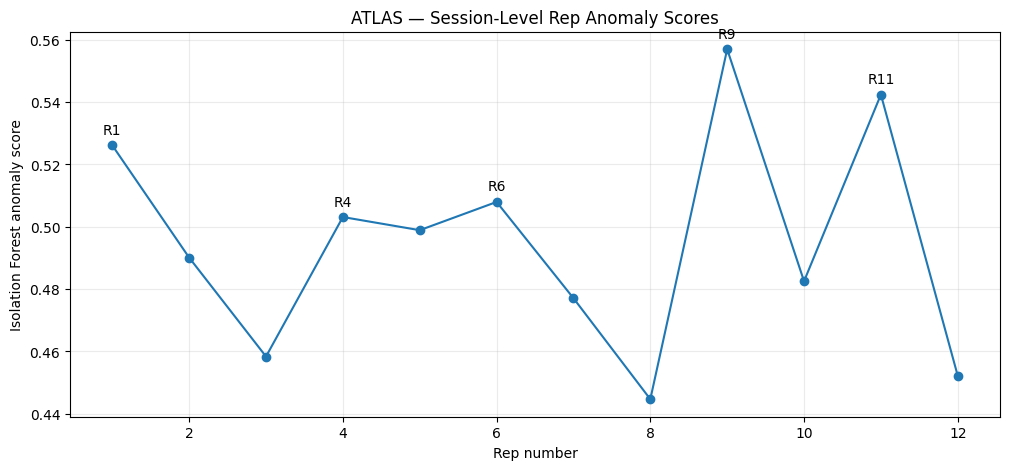

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(
    ml_df["rep_number"],
    ml_df["anomaly_score"],
    marker="o",
)

for _, row in ml_df[ml_df["is_session_anomaly"]].iterrows():
    plt.annotate(
        f"R{int(row['rep_number'])}",
        (row["rep_number"], row["anomaly_score"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
    )

plt.xlabel("Rep number")
plt.ylabel("Isolation Forest anomaly score")
plt.title("ATLAS — Session-Level Rep Anomaly Scores")
plt.grid(alpha=0.25)
plt.show()


## 9. Create observable movement labels

The supervised target should use observable movement patterns rather than medical judgments.

Recommended initial labels:
- `STABLE`
- `TORSO_DRIFT`
- `ASYMMETRIC`
- `LIMITED_ROM`

`UNSURE` is included so uncertain reps are not forced into a class.

The labels below are intentionally blank. They must be assigned from manual video review or a documented annotation process; they must not be generated from the same features used to train the classifier.


In [16]:
LABEL_COLUMN = "movement_label"

labeling_df = ml_df.copy()
labeling_df[LABEL_COLUMN] = "UNLABELED"
labeling_df["label_notes"] = ""

label_columns = [
    "rep_number",
    "start_time",
    "peak_time",
    "end_time",
    "rep_duration",
    "left_elbow_rom",
    "right_elbow_rom",
    "mean_elbow_asymmetry",
    "torso_variation",
    "anomaly_score",
    "is_session_anomaly",
    LABEL_COLUMN,
    "label_notes",
]

label_columns = [
    col for col in label_columns
    if col in labeling_df.columns
]

labeling_template = labeling_df[label_columns].copy()

display(labeling_template)


,rep_number,start_time,peak_time,end_time,rep_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,torso_variation,anomaly_score,is_session_anomaly,movement_label,label_notes
0,1,4.599974,4.999972,5.633302,1.033328,45.071363,23.985548,7.491360,19.071154,0.526110,True,UNLABELED,
1,2,8.933284,10.399942,11.599935,2.666652,83.678461,72.686589,5.325444,88.482888,0.490100,False,UNLABELED,
2,3,12.766596,14.033255,14.699918,1.933323,62.918567,81.248242,7.723067,28.357402,0.458373,False,UNLABELED,
3,4,19.199893,19.566558,21.933211,2.733318,76.671980,75.551017,13.895505,15.843483,0.503122,True,UNLABELED,
4,5,23.433203,23.833201,25.566524,2.133321,87.736454,66.502672,8.956106,102.088839,0.498902,False,UNLABELED,
5,6,26.866517,27.599846,28.533174,1.666657,84.125359,53.496989,19.032088,92.415026,0.507960,True,UNLABELED,
6,7,30.033166,31.766490,31.999822,1.966656,67.640095,70.377306,15.781223,7.284497,0.477086,False,UNLABELED,
7,8,35.199804,36.233131,37.066460,1.866656,67.687275,52.276570,18.443475,23.823295,0.444672,False,UNLABELED,
8,9,38.699784,41.833100,43.299759,4.599974,80.389579,99.871076,17.100203,67.768113,0.556957,True,UNLABELED,
9,10,45.899744,47.466402,47.799734,1.899989,76.898172,67.474954,5.045944,12.611832,0.482530,False,UNLABELED,


## 10. Save labeling template

Label this CSV after reviewing the corresponding repetitions in the original/annotated video. Later sessions should be appended to build a multi-video training dataset.


In [17]:
LABEL_CSV = Path("atlas_rep_labeling_template.csv")

labeling_template.to_csv(LABEL_CSV, index=False)

print("Saved:", LABEL_CSV)
print("Rows awaiting labels:", len(labeling_template))

# Uncomment when you want to download it.
# files.download(str(LABEL_CSV))


Saved: atlas_rep_labeling_template.csv
Rows awaiting labels: 12


## 11. Optional supervised baseline — guarded

This section runs only if `movement_label` contains real manually assigned labels from at least two classes. It deliberately refuses to train on `UNLABELED`/`UNSURE` rows or on a single class.

For a credible project metric, collect multiple videos and enough reps per class before reporting accuracy/F1 on a resume.


In [19]:
SUPERVISED_LABELS_TO_EXCLUDE = {
    "UNLABELED",
    "UNSURE",
    "",
}

if LABEL_COLUMN not in labeling_df.columns:
    print("No label column available yet.")
else:
    supervised_df = labeling_df[
        ~labeling_df[LABEL_COLUMN].isin(SUPERVISED_LABELS_TO_EXCLUDE)
    ].copy()

    class_counts = supervised_df[LABEL_COLUMN].value_counts()

    print("Labeled rows:", len(supervised_df))
    print("Class counts:")
    print(class_counts)

    can_train = (
        len(supervised_df) >= 20
        and class_counts.size >= 2
        and class_counts.min() >= 5
    )

    if not can_train:
        print(
            "Supervised training skipped. "
            "Collect more manually labeled reps across multiple videos/classes first."
        )


Labeled rows: 0
Class counts:
Series([], Name: count, dtype: int64)
Supervised training skipped. Collect more manually labeled reps across multiple videos/classes first.


## 12. Supervised training block

After enough labeled data exists, replace/reload `labeling_df` with the accumulated labeled dataset and run this cell. It compares Logistic Regression, Random Forest, and XGBoost using macro F1.


In [20]:
if "can_train" in globals() and can_train:
    X_supervised = supervised_df[FEATURE_COLUMNS].copy()
    y = supervised_df[LABEL_COLUMN].copy()

    for col in FEATURE_COLUMNS:
        X_supervised[col] = pd.to_numeric(
            X_supervised[col], errors="coerce"
        )
        X_supervised[col] = X_supervised[col].fillna(
            X_supervised[col].median()
        )

    X_train, X_test, y_train, y_test = train_test_split(
        X_supervised,
        y,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=y,
    )

    train_scaler = StandardScaler()
    X_train_scaled = train_scaler.fit_transform(X_train)
    X_test_scaled = train_scaler.transform(X_test)

    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        "XGBoost": XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=RANDOM_STATE,
            eval_metric="mlogloss",
        ),
    }

    results = []

    for name, model in models.items():
        if name == "Logistic Regression":
            model.fit(X_train_scaled, y_train)
            pred = model.predict(X_test_scaled)
        else:
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

        macro_f1 = f1_score(
            y_test,
            pred,
            average="macro",
            zero_division=0,
        )

        results.append({
            "model": name,
            "macro_f1": macro_f1,
        })

    results_df = pd.DataFrame(results).sort_values(
        "macro_f1",
        ascending=False,
    )

    display(results_df)
else:
    print("Supervised model block is waiting for enough labeled data.")


Supervised model block is waiting for enough labeled data.


## 13. Feature importance for a trained tree model

Run only after supervised training has actually occurred. Permutation importance is used so the interpretation is comparable across tree models.


In [21]:
if "can_train" in globals() and can_train:
    rf_model = models["Random Forest"]

    importance = permutation_importance(
        rf_model,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=20,
        random_state=RANDOM_STATE,
    )

    importance_df = pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std,
    }).sort_values("importance_mean", ascending=False)

    display(importance_df)

    plt.figure(figsize=(10, 5))
    plt.bar(
        importance_df["feature"],
        importance_df["importance_mean"],
    )
    plt.xticks(rotation=90)
    plt.ylabel("Permutation importance (macro F1 decrease)")
    plt.title("ATLAS — Feature Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is waiting for a trained supervised model.")


Feature importance is waiting for a trained supervised model.


## 14. Save ML-enriched rep dataset

This retains the validated rep measurements plus session-level anomaly scores. These anomaly scores are exploratory and should not be presented as form-quality or injury-risk scores.


In [22]:
ML_OUTPUT_CSV = Path("atlas_reps_ml.csv")

ml_df.to_csv(ML_OUTPUT_CSV, index=False)

print("Saved:", ML_OUTPUT_CSV)
print("Rows:", len(ml_df))
print("Features used:", len(FEATURE_COLUMNS))
print("Session anomaly candidates:", int(ml_df["is_session_anomaly"].sum()))

# files.download(str(ML_OUTPUT_CSV))


Saved: atlas_reps_ml.csv
Rows: 12
Features used: 10
Session anomaly candidates: 5


## Notebook 03 checkpoint

At this stage ATLAS can support:

`validated reps → engineered features → standardized feature space → session anomaly detection → human labeling template`

The next ML milestone is a multi-video labeled dataset large enough for honest train/validation/test evaluation of `STABLE`, `TORSO_DRIFT`, `ASYMMETRIC`, and `LIMITED_ROM`.
